# Customer happiness analysis

Predict customer happiness from six survey questions. Aim for an F1 score of at least **0.73 for happy customers (`Y=1`)**. Identify questions that a shorter survey could omit.

Reserve 12% of the responses for the final test. Tune and compare models with 10-fold stratified cross-validation on the remaining training responses.

## Setup and data loading

Run the cells in order using the project's Python environment.
Install the dependencies with `uv sync` from the project folder.

In [19]:
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.base import clone
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, f1_score
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

RANDOM_STATE = 201
F1_TARGET = 0.73
TARGET_COLUMN = "Y"
FEATURE_COLUMNS = ["X1", "X2", "X3", "X4", "X5", "X6"]

In [20]:
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "ACME-HappinessSurvey2020.csv"

raw_df = pd.read_csv(RAW_DATA_PATH)

print(f"Rows: {raw_df.shape[0]}")
print(f"Columns: {raw_df.shape[1]}")

raw_df.head()

Rows: 126
Columns: 7


,Y,X1,X2,X3,X4,X5,X6
0,0,3,3,3,4,2,4
1,0,3,2,3,5,4,3
2,1,5,3,3,3,3,5
3,0,5,4,3,3,3,5
4,0,5,4,3,3,3,5


`Y` is 0 for an unhappy customer and 1 for a happy customer.
Each question uses a score from 1 to 5; higher scores indicate more agreement.

| Feature | Survey question |
|---|---|
| X1 | My order was delivered on time. |
| X2 | The contents of my order were as I expected. |
| X3 | I ordered everything I wanted to order. |
| X4 | I paid a good price for my order. |
| X5 | I am satisfied with my courier. |
| X6 | The app makes ordering easy for me. |

## Data quality checks

In [21]:
expected_columns = [TARGET_COLUMN, *FEATURE_COLUMNS]

assert not raw_df.empty, "The dataset is empty."
assert raw_df.columns.is_unique, "Column names are not unique."
assert set(raw_df.columns) == set(expected_columns), "Unexpected or missing columns."
assert raw_df.notna().all().all(), "The dataset contains missing values."
assert raw_df[TARGET_COLUMN].isin([0, 1]).all(), "Invalid happiness label."
assert raw_df[FEATURE_COLUMNS].isin([1, 2, 3, 4, 5]).all().all(), "Invalid survey score."

pd.DataFrame(
    {
        "dtype": raw_df.dtypes,
        "missing_count": raw_df.isna().sum(),
        "unique_count": raw_df.nunique(),
    }
)

,dtype,missing_count,unique_count
Y,int64,0,2
X1,int64,0,4
X2,int64,0,5
X3,int64,0,5
X4,int64,0,5
X5,int64,0,5
X6,int64,0,5


### Repeated responses

Keep repeated responses: different customers can give the same answers.
The file has no customer identifier to establish whether records were duplicated.

An **answer pattern** is one combination of X1–X6 scores. In the table,
`row_count` counts responses and `target_count` counts distinct happiness
labels. A `target_count` of 2 means both labels occur for that pattern.

In [22]:
profile_summary = (
    raw_df.groupby(FEATURE_COLUMNS, dropna=False)
    .agg(
        row_count=(TARGET_COLUMN, "size"),
        target_count=(TARGET_COLUMN, "nunique"),
    )
    .reset_index()
)

repeated_answer_patterns = (
    profile_summary.loc[profile_summary["row_count"].gt(1)]
    .sort_values("target_count", ascending=False)
    .reset_index(drop=True)
)

print(f"Exact duplicate rows beyond the first occurrence: {raw_df.duplicated().sum()}")
print(f"Answer patterns that occur at least twice: {len(repeated_answer_patterns)}")
print(
    "Repeated answer patterns with both target labels: "
    f"{repeated_answer_patterns['target_count'].gt(1).sum()}"
)

print("\nRepeated Answer Patterns")

display(repeated_answer_patterns)

Exact duplicate rows beyond the first occurrence: 16
Answer patterns that occur at least twice: 19
Repeated answer patterns with both target labels: 7

Repeated Answer Patterns


,X1,X2,X3,X4,X5,X6,row_count,target_count
0,4,3,3,4,2,4,2,2
1,4,2,4,4,4,4,3,2
2,4,2,3,3,4,4,2,2
3,5,3,3,3,5,3,2,2
4,5,3,3,4,4,5,3,2
5,5,2,4,4,5,5,3,2
6,5,2,3,3,2,5,2,2
7,4,1,3,4,4,4,2,1
8,3,3,1,3,3,4,2,1
9,3,2,4,4,4,5,2,1


## Split the data and explore the training responses

Use `test_size=0.12` to reserve 12% of the rows for the final test.
The test count rounds up: 126 responses give 16 test responses and
110 training responses. Stratification preserves the proportions of
happy and unhappy customers as closely as possible.
Use the training responses for exploration and model selection.

In [23]:
X = raw_df[FEATURE_COLUMNS]
y = raw_df[TARGET_COLUMN]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.12, stratify=y, random_state=RANDOM_STATE
)
train_df = X_train.join(y_train)

print(f"Training responses: {len(X_train)}")
print(f"Test responses: {len(X_test)}")

Training responses: 110
Test responses: 16


In [24]:
target_summary = y_train.value_counts().reindex([0, 1]).to_frame("count")

target_summary["percentage"] = target_summary["count"].div(len(y_train)).mul(100).round(1)

target_summary

,count,percentage
Y,,
0,50,45.5
1,60,54.5


### Survey scores by happiness label

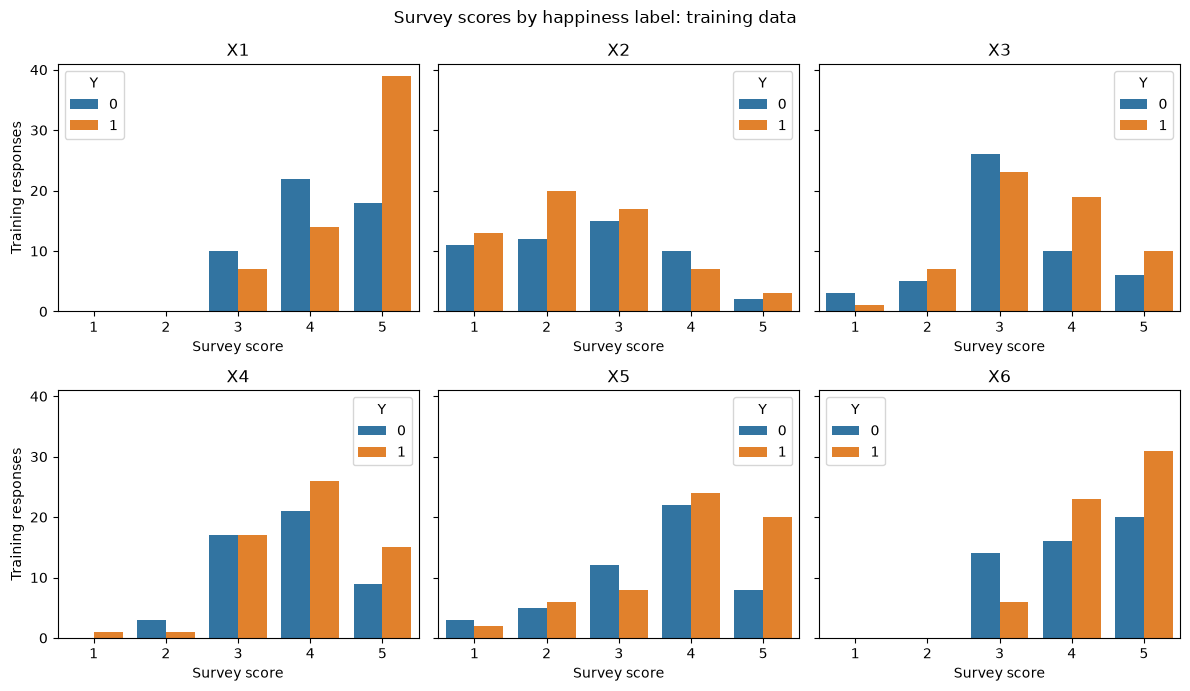

In [25]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharey=True)

for column, ax in zip(FEATURE_COLUMNS, axes.flat):
    sns.countplot(
        data=train_df,
        x=column,
        hue=TARGET_COLUMN,
        order=[1, 2, 3, 4, 5],
        hue_order=[0, 1],
        ax=ax,
    )
    ax.set_title(column)
    ax.set_xlabel("Survey score")
    ax.set_ylabel("Training responses")

fig.suptitle("Survey scores by happiness label: training data")
fig.tight_layout()
plt.show()

### Correlations

Spearman correlation compares the ranks of the survey scores. Use the
heatmap to examine relationships between questions and happiness.

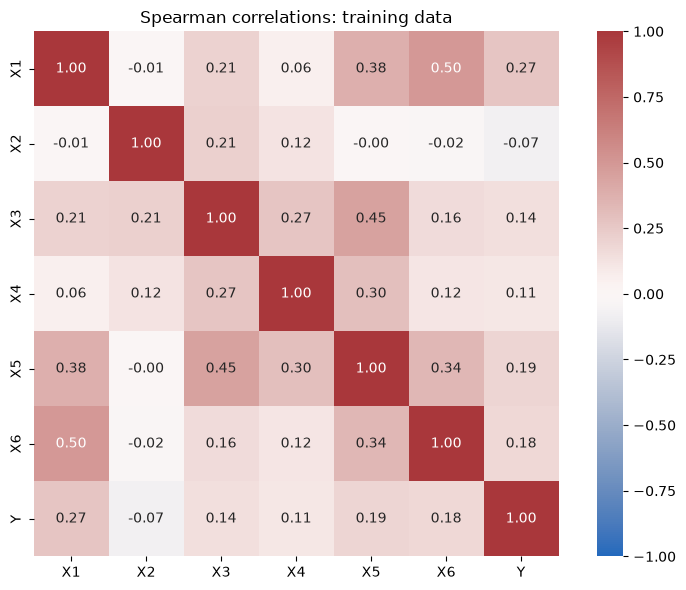

In [26]:
spearman_corr = train_df[[*FEATURE_COLUMNS, TARGET_COLUMN]].corr(method="spearman")

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0,
    cmap="vlag",
    square=True,
    ax=ax,
)

ax.set_title("Spearman correlations: training data")
fig.tight_layout()
plt.show()

## Tune and compare models

Tune all six models with the same ten folds. Each fold uses approximately
90% of the training responses for fitting and 10% for validation.
`scoring="f1"` measures F1 for happy customers (`Y=1`).
The test responses remain reserved for the final evaluation.

A pipeline fits preprocessing separately within each fold. Scale
logistic regression, KNN, and SVM. Tree models use the original scores.

The majority-class predictor provides a simple reference. It always
predicts the most frequent label in each training fold.

In [27]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
scoring = {"f1": "f1", "accuracy": "accuracy"}

models = {
    "Logistic regression": LogisticRegression(),
    "Decision tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random forest": RandomForestClassifier(random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(),
    "SVM": SVC(),
    "XGBoost": XGBClassifier(random_state=RANDOM_STATE),
}

pipelines = {}
for name, model in models.items():
    scaler = StandardScaler() if name in ["Logistic regression", "KNN", "SVM"] else "passthrough"
    pipelines[name] = Pipeline([("scale", scaler), ("model", model)])

In [28]:
dummy_scores = cross_validate(
    DummyClassifier(strategy="most_frequent"),
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
)
print(f"Majority-class mean CV F1: {dummy_scores['test_f1'].mean():.3f}")
print(f"Majority-class mean CV accuracy: {dummy_scores['test_accuracy'].mean():.3f}")

Majority-class mean CV F1: 0.706
Majority-class mean CV accuracy: 0.545


### Parameter values

Grid search checks every combination of the parameter values below.
Each model selects parameters by mean CV F1.

The `model__` prefix refers to the model step in each pipeline.

| Model | Parameters to search |
|---|---|
| Logistic regression | Regularization strength (`C`) |
| Decision tree | Tree depth and minimum samples per leaf |
| Random forest | Number of trees, depth, and minimum samples per leaf |
| KNN | Number of neighbors and neighbor weights |
| SVM | `C`, kernel, and RBF kernel width (`gamma`) |
| XGBoost | Number of trees, depth, and learning rate |

In [29]:
parameter_values = {
    "Logistic regression": {
        "model__C": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100, 300],
    },
    "Decision tree": {
        "model__max_depth": [1, 2, 3, 4, 5, 6],
        "model__min_samples_leaf": [1, 2, 4, 6, 8],
    },
    "Random forest": {
        "model__n_estimators": [50, 100, 150, 200],
        "model__max_depth": [2, 3, 4, 5, 6],
        "model__min_samples_leaf": [1, 2, 4, 6],
    },
    "KNN": {
        "model__n_neighbors": [3, 5, 7, 9, 11, 15, 19],
        "model__weights": ["uniform", "distance"],
    },
    "SVM": {
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__kernel": ["linear", "rbf"],
        "model__gamma": [0.001, 0.01, 0.1, 1],
    },
    "XGBoost": {
        "model__n_estimators": [25, 50, 100, 150],
        "model__max_depth": [1, 2, 3, 4],
        "model__learning_rate": [0.01, 0.03, 0.1, 0.3],
    },
}

### Grid search

The six grids contain 240 parameter combinations in total. Ten folds
require 2,400 fits, followed by one refit per model on all training
responses. SVM ignores `gamma` when its kernel is linear.


In [30]:
results = []
grid_searches = {}
for name, pipeline in pipelines.items():
    search = GridSearchCV(
        pipeline,
        param_grid=parameter_values[name],
        scoring=scoring,
        refit="f1",
        cv=cv,
        error_score="raise",
    )
    search.fit(X_train, y_train)
    grid_searches[name] = search
    best_index = search.best_index_
    results.append(
        {
            "model": name,
            "cv_f1": search.best_score_,
            "cv_f1_std": search.cv_results_["std_test_f1"][best_index],
            "cv_accuracy": search.cv_results_["mean_test_accuracy"][best_index],
        }
    )
    print(f"{name}: F1 = {search.best_score_:.3f}; {search.best_params_}")

Logistic regression: F1 = 0.710; {'model__C': 0.003}
Decision tree: F1 = 0.648; {'model__max_depth': 1, 'model__min_samples_leaf': 1}
Random forest: F1 = 0.666; {'model__max_depth': 4, 'model__min_samples_leaf': 1, 'model__n_estimators': 50}
KNN: F1 = 0.652; {'model__n_neighbors': 15, 'model__weights': 'distance'}
SVM: F1 = 0.706; {'model__C': 0.01, 'model__gamma': 0.001, 'model__kernel': 'rbf'}
XGBoost: F1 = 0.735; {'model__learning_rate': 0.01, 'model__max_depth': 2, 'model__n_estimators': 25}


### Compare the tuned models

Choose the tuned model with the highest mean CV F1. Compare its score
with the majority-class reference above to assess whether it improves
on always predicting the most frequent label.
These scores guide selection; the final test measures the selected model.

In [31]:
results_df = pd.DataFrame(results).sort_values("cv_f1", ascending=False).reset_index(drop=True)
display(results_df.round(3))

best_result = results_df.iloc[0]
best_name = best_result["model"]
best_pipeline = grid_searches[best_name].best_estimator_

print(f"Selected model: {best_name}")

,model,cv_f1,cv_f1_std,cv_accuracy
0,XGBoost,0.735,0.041,0.618
1,Logistic regression,0.710,0.013,0.555
2,SVM,0.706,0.000,0.545
3,Random forest,0.666,0.117,0.609
4,KNN,0.652,0.142,0.591
5,Decision tree,0.648,0.135,0.618


Selected model: XGBoost


## Select questions automatically

Keep the selected model's parameters fixed. `SelectKBest(f_classif)`
ranks each question by its association with happiness. Compare keeping
1–6 questions, fitting the selector separately within each training fold.

Choose the feature count with the highest mean CV F1. If scores tie
exactly, prefer fewer questions. Including all six provides a direct
comparison with the full survey.

In [32]:
selection_pipeline = Pipeline(
    [("select", SelectKBest(score_func=f_classif)), *clone(best_pipeline).steps]
)
feature_search = GridSearchCV(
    selection_pipeline,
    param_grid={"select__k": [1, 2, 3, 4, 5, 6]},
    scoring=scoring,
    refit=False,
    cv=cv,
    error_score="raise",
)
feature_search.fit(X_train, y_train)

feature_results = pd.DataFrame(
    {
        "questions": feature_search.cv_results_["param_select__k"].astype(int),
        "cv_f1": feature_search.cv_results_["mean_test_f1"],
        "cv_f1_std": feature_search.cv_results_["std_test_f1"],
        "cv_accuracy": feature_search.cv_results_["mean_test_accuracy"],
    }
)
best_feature_result = feature_results.sort_values(
    ["cv_f1", "questions"], ascending=[False, True]
).iloc[0]
best_k = int(best_feature_result["questions"])
display(feature_results.round(3))

# Refit after applying the preference for fewer questions on ties.
final_model = clone(selection_pipeline).set_params(select__k=best_k)
final_model.fit(X_train, y_train)

,questions,cv_f1,cv_f1_std,cv_accuracy
0,1,0.706,0.000,0.545
1,2,0.710,0.090,0.591
2,3,0.744,0.044,0.636
3,4,0.735,0.041,0.618
4,5,0.735,0.041,0.618
5,6,0.735,0.041,0.618


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('select', ...), ('scale', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['X1','X2','X3','X4','X5','X6']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"k k: int or ""all"", default=10Number of top features to select.The ""all"" option bypasses selection, for use in a parameter search.",3
,"score_func score_func: callable, default=f_classifFunction taking two arrays X and y, and returning a pair of arrays(scores, pvalues) or a single array with scores.Default is f_classif (see below ""See Also""). The default function onlyworks with classification tasks... versionadded:: 0.18",<function f_c...0022215226660>
Name,Type,Value


In [33]:
selected_mask = final_model.named_steps["select"].get_support()
selected_features = np.array(FEATURE_COLUMNS)[selected_mask].tolist()
removed_features = np.array(FEATURE_COLUMNS)[~selected_mask].tolist()

display(
    pd.DataFrame(
        {
            "question": FEATURE_COLUMNS,
            "F_statistic": final_model.named_steps["select"].scores_,
            "keep": selected_mask,
        }
    ).round(3)
)
print(f"Keep: {', '.join(selected_features)}")
print(f"Candidates to remove: {', '.join(removed_features) or 'None'}")

,question,F_statistic,keep
0,X1,7.377,True
1,X2,0.477,False
2,X3,2.229,False
3,X4,1.004,False
4,X5,3.034,True
5,X6,4.330,True


Keep: X1, X5, X6
Candidates to remove: X2, X3, X4


## Final test evaluation

The model, parameters, and questions are now fixed. Evaluate the model
on the reserved test responses once. With 16 responses, one changed
prediction moves accuracy by 6.25 percentage points.

,model,questions,test_responses,test_f1,test_accuracy,F1_target_met
0,XGBoost,3,16,0.75,0.625,True


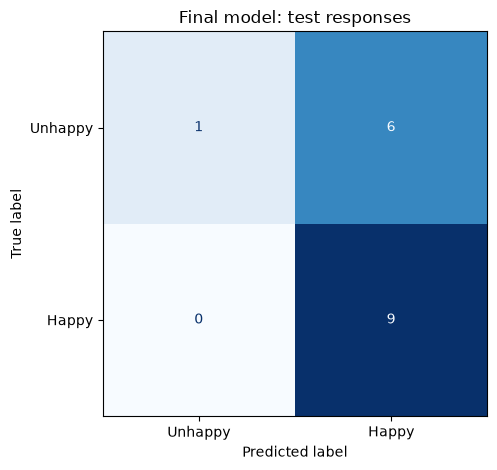

In [34]:
test_predictions = final_model.predict(X_test)
test_f1 = f1_score(y_test, test_predictions)
test_accuracy = accuracy_score(y_test, test_predictions)

display(
    pd.DataFrame(
        {
            "model": [best_name],
            "questions": [best_k],
            "test_responses": [len(y_test)],
            "test_f1": [test_f1],
            "test_accuracy": [test_accuracy],
            "F1_target_met": [test_f1 >= F1_TARGET],
        }
    ).round(3)
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=[0, 1],
    display_labels=["Unhappy", "Happy"],
    cmap="Blues",
    colorbar=False,
)
plt.title("Final model: test responses")
plt.tight_layout()
plt.show()

### Feature importance

Permutation importance measures the change in F1 when a question's
answers are shuffled. Calculate it after model selection to explain
the final test predictions. Larger positive values indicate more
reliance on that question. Dropped questions have zero importance.

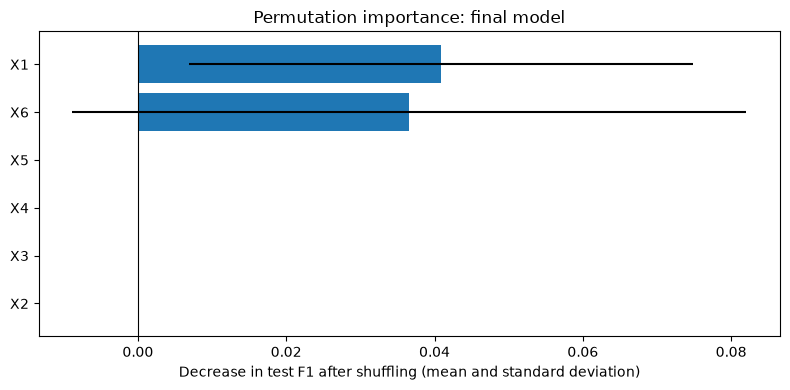

In [35]:
importance = permutation_importance(
    final_model,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=30,
    random_state=RANDOM_STATE,
)
importance_df = pd.DataFrame(
    {
        "question": FEATURE_COLUMNS,
        "mean_F1_decrease": importance.importances_mean,
        "std_F1_decrease": importance.importances_std,
    }
).sort_values("mean_F1_decrease")

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(
    importance_df["question"],
    importance_df["mean_F1_decrease"],
    xerr=importance_df["std_F1_decrease"],
)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Decrease in test F1 after shuffling (mean and standard deviation)")
ax.set_title("Permutation importance: final model")
fig.tight_layout()
plt.show()

## Findings

Use the CV comparison to assess the shorter survey. Treat removed
questions as candidates to review with the business. Confirm the result
with more customer responses before changing the survey.

In [36]:
full_survey_f1 = feature_results.loc[feature_results["questions"].eq(6), "cv_f1"].iloc[0]
selected_cv_f1 = best_feature_result["cv_f1"]

print(f"Selected model: {best_name}.")
print(f"Keep {best_k} questions: {', '.join(selected_features)}.")
print(f"CV F1: {full_survey_f1:.3f} with all six; {selected_cv_f1:.3f} with selected questions.")
print(f"Test F1: {test_f1:.3f}. Target of {F1_TARGET:.2f} met: {test_f1 >= F1_TARGET}.")
print(f"Test accuracy: {test_accuracy:.3f} on {len(y_test)} responses.")
print(f"Candidates to remove: {', '.join(removed_features) or 'None'}.")

Selected model: XGBoost.
Keep 3 questions: X1, X5, X6.
CV F1: 0.735 with all six; 0.744 with selected questions.
Test F1: 0.750. Target of 0.73 met: True.
Test accuracy: 0.625 on 16 responses.
Candidates to remove: X2, X3, X4.


## References

- [scikit-learn: cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html)
- [scikit-learn: grid search](https://scikit-learn.org/stable/modules/grid_search.html)
- [scikit-learn: feature selection](https://scikit-learn.org/stable/modules/feature_selection.html)
- [scikit-learn: pipelines and data leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)
- [scikit-learn: permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html)
- [XGBoost: scikit-learn interface](https://xgboost.readthedocs.io/en/stable/python/sklearn_estimator.html)